<a href="https://colab.research.google.com/github/jpnoug/spectropy/blob/main/SN2026sqf_suivi_Alpy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SN 2026sqf (NGC 3310) — suivi spectroscopique Alpy 600 : IIn ou Ia-CSM ?

Trois spectres 1D au format FITS (sortie ISIS), pris à cinq jours d'intervalle :

1. chaque spectre colorisé (CIE 1931 → sRGB), avec le même code couleur ;
2. annotation des raies signatures d'une **type II** (série de Balmer, He I) et d'une **type Ia**
   (Si II, S II) ;
3. largeur instrumentale mesurée sur la lampe Ne+Ar de la nuit du 28 juillet ;
4. **FWHM de Hα**, déconvoluée : la composante étroite trace un gaz circumstellaire lent
   (< 1000 km/s) ;
5. pseudo-largeur équivalente de Si II 6355 à chaque époque ;
6. planches de suivi temporel : flux relatif brut, puis spectres normalisés.

**L'enjeu.** Une SN Ia qui explose dans un milieu circumstellaire dense riche en hydrogène (Ia-CSM)
montre des raies de Balmer étroites. L'interaction ajoute aussi un continu bleu qui *dilue* les
absorptions de la Ia sous-jacente. Tant que cette dilution domine, le spectre est celui d'une IIn :
la classification ne peut venir que des signatures de Ia qui finissent par émerger.

Observation : Newton 200 + Alpy 600 (fente 23 µm) + Atik 414EX, site PBO. R ≈ 480–500 selon l'en-tête ;
la résolution mesurée sur la lampe est donnée au §5.

## 1 — Chargement des spectres

In [1]:
import numpy as np, matplotlib.pyplot as plt, os, glob
from matplotlib.patches import Polygon
from astropy.io import fits
from astropy.time import Time
from scipy.ndimage import uniform_filter1d

trapz = getattr(np, "trapezoid", None) or np.trapz          # numpy >= 2 / < 2
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

FITS_PATHS = ["_sn2026sqf_20260718_887_extcorr.fits",      # <- adapter si besoin
              "sn2026sqf_20260723_extcorr.fits",
              "sn2026sqf_20260728_extcorr.fits"]

N_SPECTRES = 3                                             # nombre de spectres a charger

presents = [p for p in FITS_PATHS if os.path.exists(p)]
if len(presents) < N_SPECTRES:                             # deja televerses sous un autre nom ?
    presents = sorted(set(presents) | set(glob.glob("*sqf*.fits")))
if len(presents) < N_SPECTRES:
    try:                                                   # Colab : un selecteur par spectre,
        from google.colab import files                     # chacun pouvant viser un dossier different
        while len(presents) < N_SPECTRES:
            print(f"spectre {len(presents) + 1}/{N_SPECTRES} : choisir le fichier FITS "
                  f"(plusieurs a la fois possible ; Annuler pour arreter)")
            recus = files.upload()
            if not recus:
                break
            presents += [f for f in recus if f not in presents]
    except ImportError:
        pass
if not presents:
    raise FileNotFoundError("aucun spectre FITS trouve")
FITS_PATHS = presents

OBJET   = "SN 2026sqf"
HOTE    = "NGC 3310"
Z_HOTE  = 0.00331                   # NGC 3310, cz = 993 km/s
C_KMS   = 299792.458
JD_DECOUVERTE = Time("2026-07-08T00:00:00", scale="utc").jd + 0.251   # 8,251 juillet (Wiggins)

def charge(path):
    hdu  = fits.open(path)[0]
    hdr  = hdu.header
    flux = hdu.data.astype(float)
    wave = hdr["CRVAL1"] + hdr["CDELT1"] * (np.arange(flux.size) + 1 - hdr.get("CRPIX1", 1))
    ok   = np.isfinite(flux) & (flux > 0)                   # bords a zero eventuels
    i0, i1 = np.argmax(ok), ok.size - np.argmax(ok[::-1])
    jd = hdr.get("JD-MID") or (Time(hdr["DATE-OBS"]).jd + hdr.get("EXPTIME", 0) / 172800)
    return dict(path=path, hdr=hdr, wave=wave[i0:i1], flux=flux[i0:i1],
                date=hdr.get("DATE-OBS", "?")[:10], jd=jd, phase=jd - JD_DECOUVERTE,
                R=float(hdr.get("BSS_ITRP") or hdr.get("SPE_RPOW") or 500),
                pose=hdr.get("EXPTIME2", ""))

SPECTRES = sorted((charge(p) for p in FITS_PATHS), key=lambda s: s["jd"])
for s in SPECTRES:
    s["label"] = f"{s['date']}  (J+{s['phase']:.1f})"

print(f"{'date':12s}{'phase':>8s}{'domaine (A)':>17s}{'R':>6s}   pose        fichier")
for s in SPECTRES:
    print(f"{s['date']:12s}{s['phase']:7.1f}j{s['wave'][0]:9.0f}-{s['wave'][-1]:.0f}"
          f"{s['R']:6.0f}   {s['pose']:11s} {os.path.basename(s['path'])}")
    for h in s["hdr"].get("HISTORY", []):
        print("      ", h)

spectre 1/3 : choisir le fichier FITS (plusieurs a la fois possible ; Annuler pour arreter)


Saving _sn2026sqf_20260718_887_extcorr.fits to _sn2026sqf_20260718_887_extcorr.fits
spectre 2/3 : choisir le fichier FITS (plusieurs a la fois possible ; Annuler pour arreter)


Saving sn2026sqf_20260723_extcorr.fits to sn2026sqf_20260723_extcorr.fits
spectre 3/3 : choisir le fichier FITS (plusieurs a la fois possible ; Annuler pour arreter)


Saving sn2026sqf_20260728_extcorr.fits to sn2026sqf_20260728_extcorr.fits
date           phase      domaine (A)     R   pose        fichier
2026-07-18     10.6j     3800-7375   500   3 x 600 s   _sn2026sqf_20260718_887_extcorr.fits
2026-07-23     15.7j     3700-7577   501   6 x 600 s   sn2026sqf_20260723_extcorr.fits
       Differential atmospheric extinction correction, dX(ref-SN)=0.071
       k(lambda)=Rayleigh+aerosol(0.10) mag/airmass; factor=10^(-0.4 k dX)
2026-07-28     20.6j     3780-7569   482   6 x 600 s   sn2026sqf_20260728_extcorr.fits
       Differential atmospheric extinction correction, dX(ref-SN)=0.244
       k(lambda)=Rayleigh+aerosol(0.10) mag/airmass; factor=10^(-0.4 k dX)


## 2 — Colorimétrie : longueur d'onde → couleur perçue

Même chaîne que pour SN 2026aaiv : λ → XYZ (CIE 1931 2°, approximation de Wyman, Sloan & Shirley
2013) → sRGB. `GAMMA` règle la modulation de la luminance par le flux, `EYE` le dosage de la
sensibilité photopique V(λ). La teinte est figée hors de 400–660 nm.

In [2]:
def _lobe(x, mu, s1, s2):
    s = np.where(x < mu, s1, s2)
    return np.exp(-0.5 * ((x - mu) / s) ** 2)

def cie_xyz(lam_nm):
    """Fonctions colorimetriques CIE 1931 2 deg (Wyman, Sloan & Shirley 2013)."""
    x = (1.056 * _lobe(lam_nm, 599.8, 37.9, 31.0)
         + 0.362 * _lobe(lam_nm, 442.0, 16.0, 26.7)
         - 0.065 * _lobe(lam_nm, 501.1, 20.4, 26.2))
    y = (0.821 * _lobe(lam_nm, 568.8, 46.9, 40.5)
         + 0.286 * _lobe(lam_nm, 530.9, 16.3, 31.1))
    z = (1.217 * _lobe(lam_nm, 437.0, 11.8, 36.0)
         + 0.681 * _lobe(lam_nm, 459.0, 26.0, 13.8))
    return np.stack([x, y, z], axis=-1)

XYZ2RGB = np.array([[ 3.2406, -1.5372, -0.4986],
                    [-0.9689,  1.8758,  0.0415],
                    [ 0.0557, -0.2040,  1.0570]])

def _srgb_gamma(c):
    c = np.clip(c, 0, 1)
    return np.where(c <= 0.0031308, 12.92 * c, 1.055 * c ** (1 / 2.4) - 0.055)

def spectre_rgb(lam_A, f, gamma=0.7, eye=0.3):
    """Couleur sRGB de chaque colonne : teinte de la longueur d'onde, luminance
    (flux/flux_max)**gamma * V(lambda)**eye."""
    lam_nm = lam_A / 10.0
    xyz = cie_xyz(np.clip(lam_nm, 400., 660.))       # teinte figee hors [400, 660] nm
    rgb = np.maximum(xyz @ XYZ2RGB.T, 0.0)
    mx  = rgb.max(axis=1, keepdims=True)
    teinte = np.where(mx > 1e-9, rgb / np.maximum(mx, 1e-9), 0.0)

    V = cie_xyz(lam_nm)[:, 1]
    V = V / V.max()
    lum = (np.clip(f, 0, None) / np.nanmax(f)) ** gamma * V ** eye
    return _srgb_gamma(teinte * (lum / np.nanmax(lum))[:, None])

## 3 — Les trois spectres colorisés, chacun pour lui-même

Mêmes réglages (`GAMMA`, `EYE`, `LISSAGE`) pour les trois : seule la forme du spectre fait varier
le rendu. Chaque figure a sa propre échelle verticale ; la comparaison quantitative est en §8.

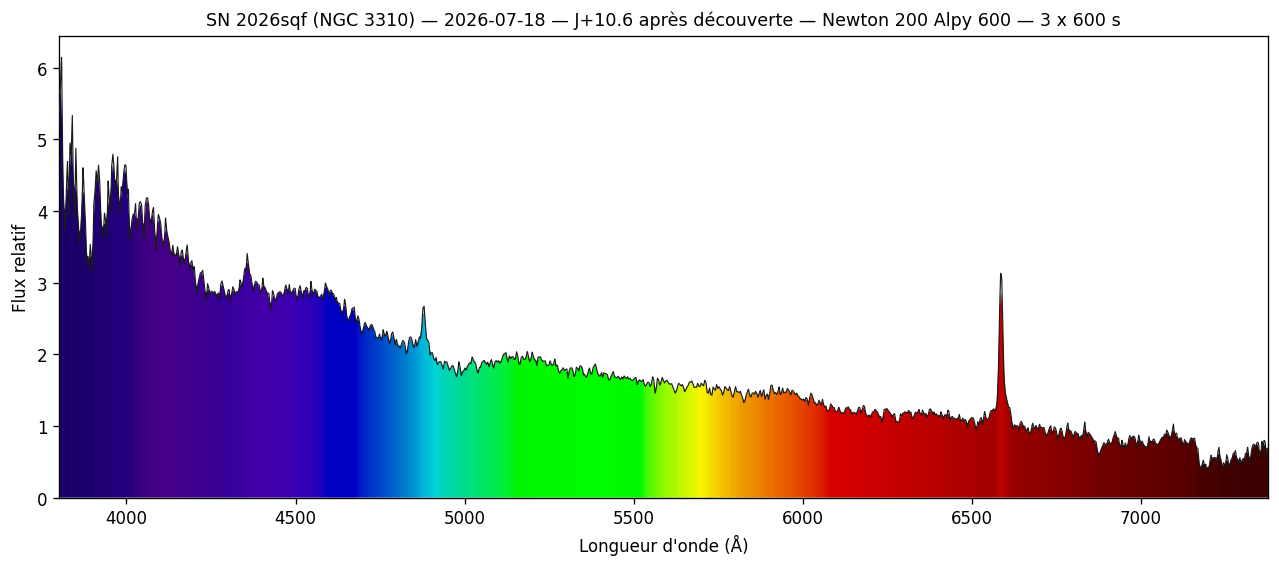

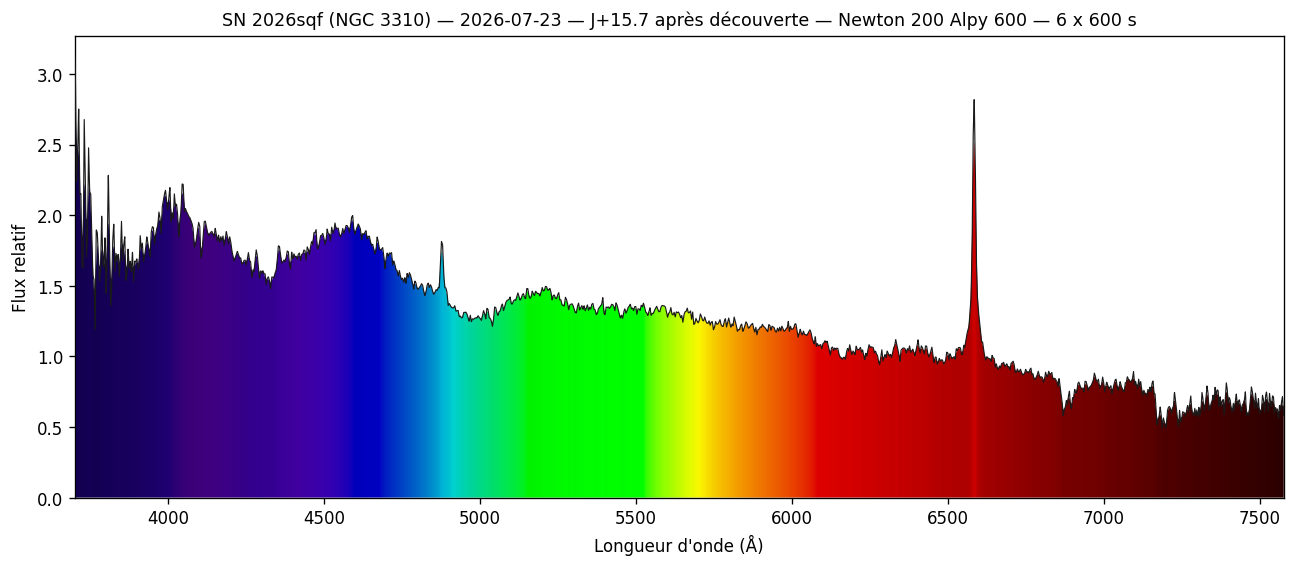

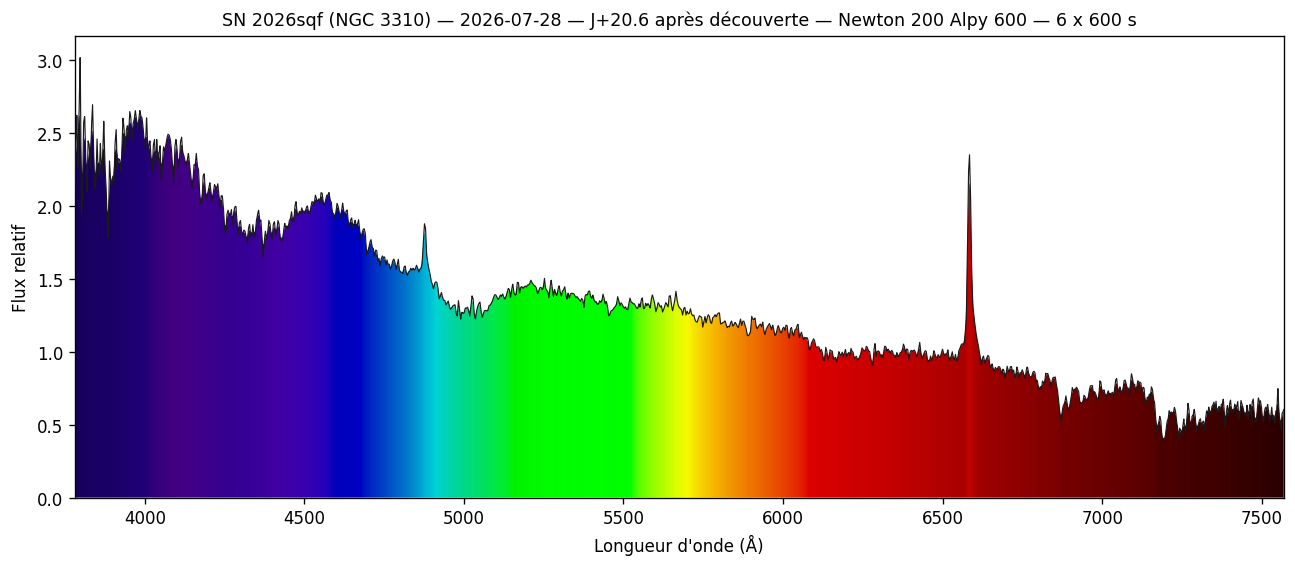

In [3]:
GAMMA   = 0.5      # contraste de la modulation par le flux (0 = teinte pleine)
EYE     = 0.3      # part de sensibilite photopique (0 = arc-en-ciel plein, 1 = oeil complet)
LISSAGE = 21       # px, pour la couleur et le contour de l'aire seulement

for s in SPECTRES:
    s["flux_l"] = uniform_filter1d(s["flux"], LISSAGE)

def trace_spectre(ax, s, gamma=GAMMA, eye=EYE, ymax=None, courbe=True):
    """Remplit l'aire sous la courbe avec le degrade spectral."""
    wave, flux, flux_l = s["wave"], s["flux"], s["flux_l"]
    ymax = ymax or np.nanmax(flux) * 1.05
    rgb  = spectre_rgb(wave, flux_l, gamma=gamma, eye=eye)
    img  = ax.imshow(np.tile(rgb[None], (2, 1, 1)), aspect="auto", origin="lower",
                     extent=[wave[0], wave[-1], 0, ymax], interpolation="bilinear", zorder=0)
    contour = np.column_stack([np.r_[wave[0], wave, wave[-1]], np.r_[0, flux_l, 0]])
    img.set_clip_path(Polygon(contour, transform=ax.transData, closed=True))
    if courbe:
        ax.plot(wave, flux, lw=0.7, color="0.10", zorder=3)
    ax.set_xlim(wave[0], wave[-1]); ax.set_ylim(0, ymax)
    ax.set_xlabel("Longueur d'onde (Å)"); ax.set_ylabel("Flux relatif")
    return ymax

def titre(s, extra=""):
    return (f"{OBJET} ({HOTE}) — {s['date']} — J+{s['phase']:.1f} après découverte — "
            f"Newton 200 Alpy 600 — {s['pose']}{extra}")

for s in SPECTRES:
    fig, ax = plt.subplots(figsize=(13, 5))
    trace_spectre(ax, s)
    ax.set_title(titre(s), fontsize=10.5)
    plt.show()

## 4 — Signatures de type II et de type Ia

Deux familles de repères, qui ne se placent pas de la même façon :

* **Raies d'émission de l'hydrogène et de l'hélium** (rouge) — émises par le gaz circumstellaire,
  quasi au repos : on les marque au décalage de l'hôte (z = 0,00331). Hγ, Hβ, Hα et He I 5876.
* **Absorptions de la Ia sous-jacente** (bleu) — formées dans des éjecta en expansion rapide, donc
  décalées vers le bleu. Leur position n'est pas connue d'avance : on ombre la plage attendue pour
  une vitesse photosphérique de 8 000 à 14 000 km/s. Si II 6355, Si II 5972, et le « W » de S II
  (5454 / 5640).
* **Na I D** (gris) en absorption : interstellaire, dans NGC 3310 (5912 Å) et dans la Voie lactée
  (5893 Å). À R ≈ 500, Na I D galactique tombe à 2 Å de He I 5876 de l'hôte : les deux se mélangent.
* **Bandes telluriques** (hachures) : le spectre n'est pas corrigé de l'absorption atmosphérique
  (`BSS_TELL = None`). Les creux à 6870, 7200 et 7600 Å ne sont pas stellaires.

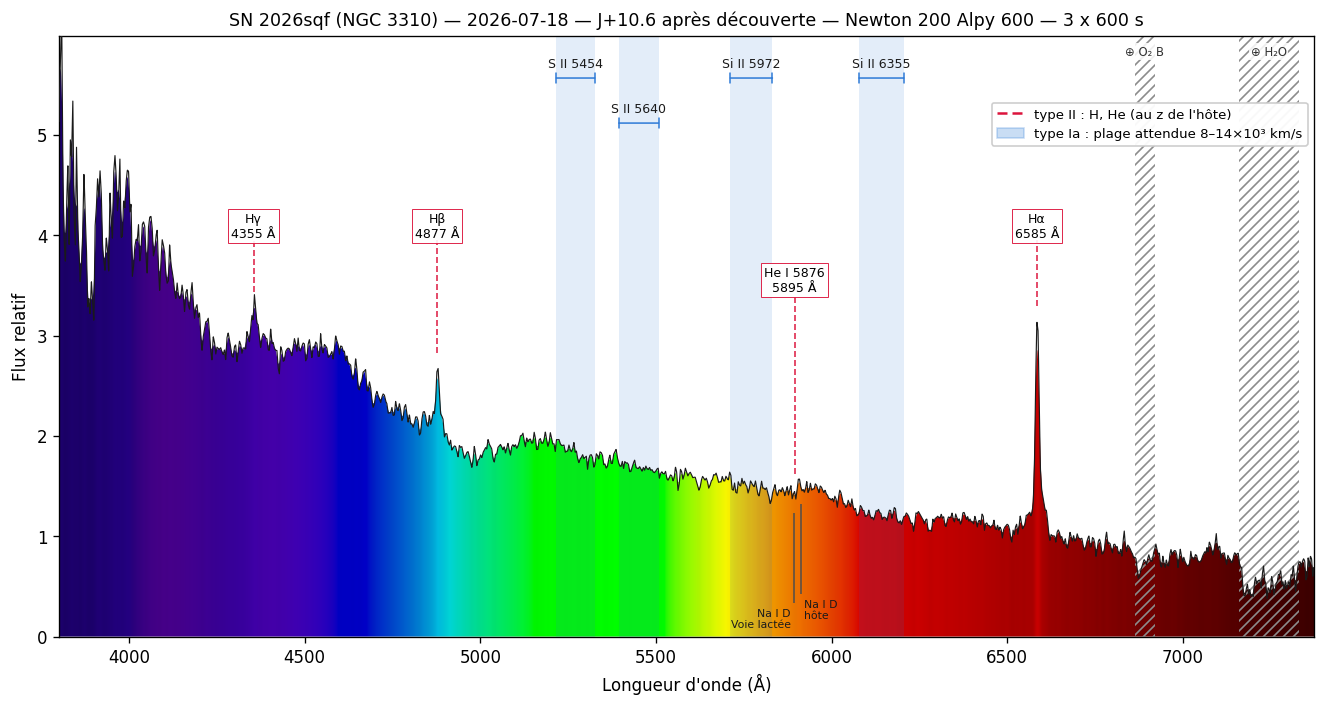

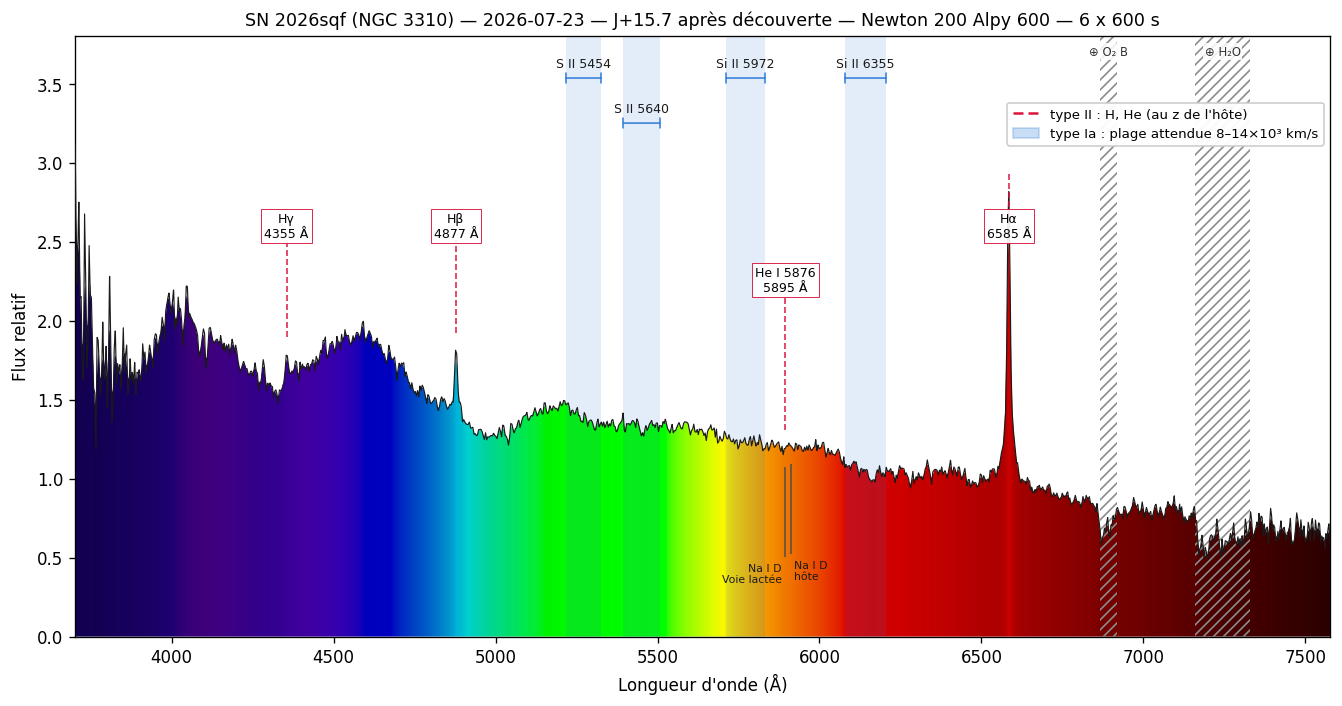

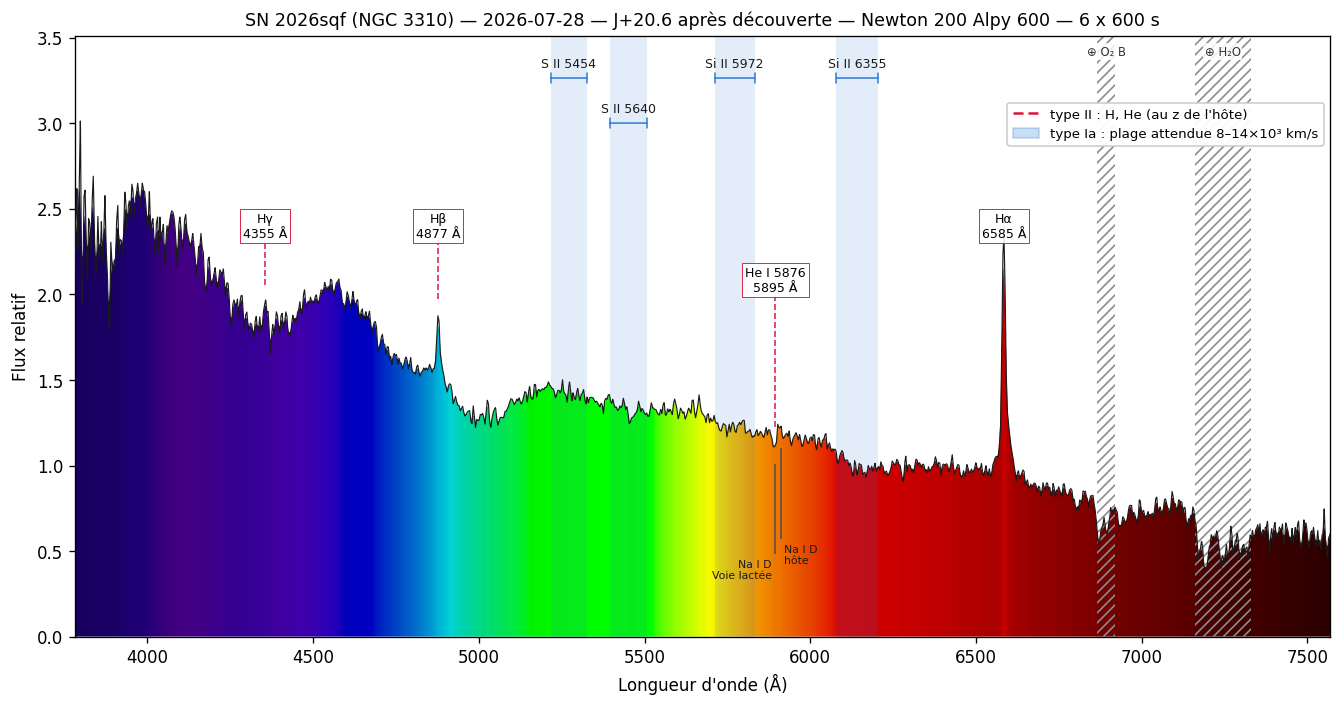

In [4]:
COUL_II, COUL_IA, COUL_NA = "crimson", "#2a78d6", "0.30"
V_IA = (8000, 14000)                     # km/s, plage photospherique d'une Ia

# raies d'emission au repos dans l'hote : (lambda_repos, libelle, niveau d'etiquette)
EMISSION = [(4340.47, "Hγ",        0),
            (4861.33, "Hβ",        0),
            (5875.62, "He I 5876", 1),
            (6562.80, "Hα",        0)]
# absorptions Ia : (lambda_repos, libelle, niveau)
ABS_IA   = [(5454, "S II 5454", 0), (5640, "S II 5640", 1),
            (5972, "Si II 5972", 0), (6355, "Si II 6355", 0)]
NA_D     = [(5892.9 * (1 + Z_HOTE), "Na I D\nhôte"), (5892.9, "Na I D\nVoie lactée")]
TELLUR   = [(6865, 6920, "⊕ O₂ B"), (7160, 7330, "⊕ H₂O"), (7590, 7700, "⊕ O₂ A")]

def bande_ia(lam0):
    """Plage observee [bleu, rouge] pour V_IA, dans le referentiel de l'hote."""
    l = lam0 * (1 + Z_HOTE)
    return l * (1 - V_IA[1] / C_KMS), l * (1 - V_IA[0] / C_KMS)

def annote(ax, s, ymax):
    wave, fl = s["wave"], s["flux_l"]
    for a, b, lab in TELLUR:
        if a < wave[-1]:
            ax.axvspan(a, min(b, wave[-1]), fc="none", ec="0.55", hatch="////", lw=0, zorder=1)
            ax.text((a + min(b, wave[-1])) / 2, ymax * 0.985, lab, ha="center", va="top",
                    fontsize=7, color="0.2", zorder=5,
                    bbox=dict(fc="white", ec="none", alpha=0.85, pad=1))
    for lam0, lab, niv in ABS_IA:
        a, b = bande_ia(lam0)
        ax.axvspan(a, b, color=COUL_IA, alpha=0.13, lw=0, zorder=1)
        y = ymax * (0.93 - 0.075 * niv)
        ax.annotate("", (a, y), (b, y), arrowprops=dict(arrowstyle="|-|", color=COUL_IA,
                    lw=0.9, shrinkA=0, shrinkB=0, mutation_scale=3), zorder=5)
        ax.text((a + b) / 2, y + ymax * 0.012, lab, ha="center", va="bottom", fontsize=7.5,
                color="0.1", zorder=5)
    for lam0, lab, niv in EMISSION:
        w0 = lam0 * (1 + Z_HOTE)
        y0 = np.interp(w0, wave, s["flux"]) if lab.startswith("H") else np.interp(w0, wave, fl)
        y1 = ymax * (0.66 - 0.09 * niv)
        ax.vlines(w0, y0 + ymax * 0.03, y1, color=COUL_II, lw=0.9, ls=(0, (4, 2)), zorder=4)
        ax.text(w0, y1, f"{lab}\n{w0:.0f} Å", ha="center", va="bottom", fontsize=7.5,
                linespacing=1.2, zorder=5,
                bbox=dict(fc="white", ec=COUL_II, lw=0.6, alpha=0.9, pad=1.8))
    for k, (w0, lab) in enumerate(NA_D):
        y0 = np.interp(w0, wave, fl)
        ax.vlines(w0, y0 - ymax * 0.18, y0 - ymax * 0.03, color=COUL_NA, lw=0.9, zorder=4)
        ax.text(w0 + (9 if k == 0 else -9), y0 - ymax * 0.19, lab, ha="left" if k == 0 else "right",
                va="top", fontsize=6.5, color="0.1", linespacing=1.1, zorder=5)

for s in SPECTRES:
    fig, ax = plt.subplots(figsize=(13.5, 6.5))
    ymax = trace_spectre(ax, s, ymax=np.nanmax(s["flux"][s["wave"] > 4000]) * 1.35)
    annote(ax, s, ymax)
    ax.set_title(titre(s), fontsize=10.5)
    ax.plot([], [], color=COUL_II, ls=(0, (4, 2)), label="type II : H, He (au z de l'hôte)")
    ax.fill_between([], [], color=COUL_IA, alpha=0.25,
                    label=f"type Ia : plage attendue {V_IA[0]//1000}–{V_IA[1]//1000}×10³ km/s")
    ax.legend(fontsize=8, loc="upper right", bbox_to_anchor=(1, 0.90), framealpha=0.95)
    plt.show()

## 5 — Largeur instrumentale mesurée sur la lampe de calibration

L'en-tête donne R ≈ 500, une valeur « typique ». La résolution réelle se mesure sur la lampe de la
même nuit : `mneon.fits` est la moyenne de 5 poses brutes 2D de la nuit du 28 juillet. On la suppose
valable pour les deux autres nuits, avec le même montage.

1. **Extraction.** On repère la hauteur de fente éclairée et on moyenne une bande de lignes en son
   centre. Les raies de la lampe sont courbées le long de la fente : une bande étroite évite de les
   élargir artificiellement. Le fond est la médiane des lignes situées hors de la fente.
2. **Identification.** On cherche la loi pixel → λ qui fait coïncider le plus de pics avec la liste
   de raies, puis on l'affine par un polynôme de degré 3. Le module de calibration de l'Alpy
   contient aussi de l'**argon** : les raies fortes au-delà de 6900 Å sont des raies d'Ar I.
3. **Largeur.** On ne garde que les raies non saturées, isolées et voisines de Hα, puis on
   interpole leur FWHM à la longueur d'onde de Hα. Deux estimateurs :
   * **ajustement gaussien sur les pixels bruts** : la résolution optique vraie, d'où R ;
   * **mi-hauteur après ré-échantillonnage à 0,5 Å/px** : la même méthode et la même grille que
     pour la raie Hα des spectres ISIS. **C'est celle-là qu'on retire de la FWHM de Hα.**

L'écart entre les deux vient de l'échantillonnage. Une raie ne couvre que ~3 pixels bruts à
mi-hauteur. Son sommet tombe en général entre deux pixels, et l'interpolation ne le retrouve pas :
le pic ré-échantillonné est plus bas, donc la mi-hauteur plus basse et la raie plus large. Les
spectres ISIS subissent exactement le même effet, d'où la nécessité de comparer avec le même
estimateur sur la même grille.

In [5]:
from scipy.signal import find_peaks
from scipy.optimize import curve_fit
from scipy.interpolate import CubicSpline
from itertools import combinations
import warnings
from scipy.optimize import OptimizeWarning
warnings.simplefilter("ignore", OptimizeWarning)

NEON_PATH  = "mneon.fits"             # <- adapter si besoin ; None = repli sur le R de l'en-tete
DEMI_BANDE = 5                        # lignes, demi-hauteur de la bande extraite
FEN_INST   = (6200, 7100)             # A, raies retenues pour interpoler la largeur a Hα
SATURATION = 60000                    # ADU
AMP_MIN    = 1000                     # ADU, amplitude minimale d'une raie retenue
HA         = 6562.8 * (1 + Z_HOTE)

# raies de la lampe Alpy (Ne I + Ar I), longueurs d'onde dans l'air
RAIES_LAMPE = {5852.49: "Ne", 5881.90: "Ne", 5944.83: "Ne", 5975.53: "Ne", 6030.00: "Ne",
               6074.34: "Ne", 6096.16: "Ne", 6143.06: "Ne", 6163.59: "Ne", 6217.28: "Ne",
               6266.50: "Ne", 6304.79: "Ne", 6334.43: "Ne", 6382.99: "Ne", 6402.25: "Ne",
               6506.53: "Ne", 6532.88: "Ne", 6598.95: "Ne", 6678.28: "Ne", 6717.04: "Ne",
               6929.47: "Ne", 6965.43: "Ar", 7032.41: "Ne", 7067.22: "Ar", 7147.04: "Ar",
               7272.94: "Ar", 7383.98: "Ar", 7503.87: "Ar", 7635.11: "Ar"}
L_LAMPE = np.array(sorted(RAIES_LAMPE))

def largeur_mi_hauteur(wave, y, centre, fen=25):
    """FWHM du pic de y (continu deja soustrait) le plus haut a +/- fen A de centre,
    par interpolation lineaire des deux passages a mi-hauteur."""
    m  = np.where(np.abs(wave - centre) < fen)[0]
    i0 = m[np.argmax(y[m])]
    demi = y[i0] / 2
    j = i0
    while y[j] > demi: j -= 1
    wb = wave[j] + (demi - y[j]) / (y[j + 1] - y[j]) * (wave[j + 1] - wave[j])
    j = i0
    while y[j] > demi: j += 1
    wr = wave[j - 1] + (demi - y[j - 1]) / (y[j] - y[j - 1]) * (wave[j] - wave[j - 1])
    return wr - wb, wave[i0], y[i0], wb, wr

if NEON_PATH and not os.path.exists(NEON_PATH):
    try:
        from google.colab import files
        print("selectionner le fichier de la lampe (mneon.fits)")
        NEON_PATH = list(files.upload().keys())[0]
    except (ImportError, IndexError):
        NEON_PATH = None

INST = None
if NEON_PATH:
    img = fits.getdata(NEON_PATH).astype(float)

    # --- 1. extraction ----------------------------------------------------------------
    prof  = np.median(img, axis=1)
    seuil = prof.min() + 0.5 * (prof.max() - prof.min())
    lignes = np.where(prof > seuil)[0]
    r_bas, r_haut = lignes[0], lignes[-1]
    r_c   = (r_bas + r_haut) // 2
    hors  = np.r_[np.arange(0, max(r_bas - 40, 1)), np.arange(min(r_haut + 40, img.shape[0] - 1), img.shape[0])]
    fond  = np.median(img[hors], axis=0)
    bande = img[r_c - DEMI_BANDE:r_c + DEMI_BANDE + 1]
    neon  = bande.mean(axis=0) - fond
    xpix  = np.arange(neon.size)
    print(f"fente eclairee : lignes {r_bas}-{r_haut}, bande extraite {r_c}±{DEMI_BANDE}")

    # --- 2. pics, ajustements gaussiens, identification --------------------------------
    def g(x, a, mu, sig, c0, c1):
        return a * np.exp(-0.5 * ((x - mu) / sig) ** 2) + c0 + c1 * (x - mu)

    pics, _ = find_peaks(neon, prominence=0.005 * neon.max(), distance=3)
    P = []                    # (centre, sigma_px, amplitude, max brut, fond c0, pente c1)
    for p in pics:
        m = np.abs(xpix - p) <= 6
        try:
            par, _ = curve_fit(g, xpix[m], neon[m], p0=[neon[p], p, 1.3, 0, 0], maxfev=4000)
        except RuntimeError:
            continue
        if abs(par[1] - p) < 2 and 0.5 < abs(par[2]) < 5:
            P.append((par[1], abs(par[2]), par[0], bande[:, max(p - 3, 0):p + 4].max(),
                      par[3], par[4]))
    P = np.array(P)
    xc = P[:, 0]

    fortes = xc[np.argsort(P[:, 2])[-14:]]           # recherche de la loi lineaire sur les plus forts
    meilleur = (0,)
    for x1, x2 in combinations(np.sort(fortes), 2):
        for l1, l2 in combinations(L_LAMPE, 2):
            b = (l2 - l1) / (x2 - x1)
            if not 2.0 < b < 5.0:
                continue
            lam = l1 + b * (xc - x1)
            n = (np.abs(lam[:, None] - L_LAMPE[None]).min(axis=1) < 6).sum()
            if n > meilleur[0]:
                meilleur = (n, l1 - b * x1, b)
    coef = [meilleur[2], meilleur[1]]
    for tol in (8, 6, 4, 3):                          # affinage : degre 1 puis 3
        lam = np.polyval(coef, xc)
        dist = np.abs(lam[:, None] - L_LAMPE[None])
        ok = dist.min(axis=1) < tol
        coef = np.polyfit(xc[ok], L_LAMPE[dist.argmin(axis=1)[ok]], 3 if ok.sum() > 8 else 1)
    lam  = np.polyval(coef, xc)
    dist = np.abs(lam[:, None] - L_LAMPE[None])
    ident = dist.min(axis=1) < 3
    lref  = L_LAMPE[dist.argmin(axis=1)]
    disp  = np.polyval(np.polyder(coef), xc)         # A/px local
    res   = (lam - lref)[ident]
    print(f"{ident.sum()} raies identifiees, residus rms = {res.std():.2f} A, "
          f"dispersion {disp.min():.2f}-{disp.max():.2f} A/px")

    # --- 3. largeurs ----------------------------------------------------------------------
    # melangee : un autre pic a moins de 7 px et d'au moins 15 % de son amplitude,
    # ou une autre raie du catalogue a moins de 22 A (pic voisin non detecte, ex. 6383/6402)
    isolee = np.array([not np.any((np.abs(xc - xc[k]) > 0) & (np.abs(xc - xc[k]) < 7)
                                  & (P[:, 2] > 0.15 * P[k, 2])) for k in range(xc.size)])
    isolee &= np.array([np.sort(np.abs(L_LAMPE - l))[1] > 22 for l in lref])
    sature = P[:, 3] >= SATURATION
    assez  = P[:, 2] > AMP_MIN                       # raies faibles : mi-hauteur trop bruitee
    retenue = ident & isolee & ~sature & assez & (lref > FEN_INST[0]) & (lref < FEN_INST[1])

    fw_gauss = 2.3548 * P[:, 1] * disp               # A
    m_neon = xpix > xc.min() - 50
    lam_px = np.polyval(coef, xpix[m_neon])
    grille = np.arange(lam_px[0], lam_px[-1], 0.5)
    fw_lin = np.full(xc.size, np.nan); fw_cub = np.full(xc.size, np.nan)
    neon_lin = np.interp(grille, lam_px, neon[m_neon])
    neon_cub = CubicSpline(lam_px, neon[m_neon])(grille)
    x_grille = np.interp(grille, lam_px, xpix[m_neon])
    for k in np.where(ident & ~sature)[0]:
        base = P[k, 4] + P[k, 5] * (x_grille - xc[k])   # fond local issu de l'ajustement gaussien
        fw_lin[k] = largeur_mi_hauteur(grille, neon_lin - base, lref[k], fen=8)[0]
        fw_cub[k] = largeur_mi_hauteur(grille, neon_cub - base, lref[k], fen=8)[0]
    fw_demi = (fw_lin + fw_cub) / 2                  # interpolation d'ISIS inconnue : moyenne

    print(f"\n{'raie':>9s}      {'x (px)':>8s}{'pic':>8s}{'gauss':>8s}{'mi-haut.':>10s}{'R gauss':>9s}  remarque")
    for k in np.argsort(lref):
        if not ident[k]:
            continue
        rq = ("SATUREE" if sature[k] else "melangee" if not isolee[k] else
              "faible" if not assez[k] else "retenue" if retenue[k] else "")
        print(f"{lref[k]:9.2f} {RAIES_LAMPE[lref[k]]:3s}{xc[k]:9.1f}{P[k, 3]:8.0f}"
              f"{fw_gauss[k]:8.2f}{fw_demi[k]:9.2f} Å{lref[k] / fw_gauss[k]:8.0f}  {rq}")

    def a_ha(fw):
        """FWHM interpolee a Hα (droite en λ) et dispersion des raies autour de cette droite."""
        p = np.polyfit(lref[retenue], fw[retenue], 1)
        return np.polyval(p, HA), np.std(fw[retenue] - np.polyval(p, lref[retenue]), ddof=2), p

    g_ha, g_sig, g_p = a_ha(fw_gauss)
    d_ha, d_sig, d_p = a_ha(fw_demi)
    INST = dict(fwhm=d_ha, sig=d_sig, fwhm_gauss=g_ha, sig_gauss=g_sig, R=HA / g_ha,
                source="lampe Ne+Ar, mi-hauteur à 0,5 Å/px")
    print(f"\nA Hα ({HA:.0f} A), {retenue.sum()} raies :")
    print(f"  ajustement gaussien (resolution optique)  FWHM = {g_ha:5.2f} ± {g_sig:.2f} A"
          f"   R = {HA / g_ha:.0f}   ({g_ha / HA * C_KMS:.0f} km/s)")
    print(f"  mi-hauteur sur grille 0,5 A (comme ISIS)   FWHM = {d_ha:5.2f} ± {d_sig:.2f} A"
          f"   ({d_ha / HA * C_KMS:.0f} km/s)   <- retenue")
    print(f"  pour memoire, en-tete : λ/R = {HA / SPECTRES[-1]['R']:.2f} A")

if INST is None:                                     # repli : R de l'en-tete
    R_moy = np.mean([s["R"] for s in SPECTRES])
    INST = dict(fwhm=HA / R_moy, sig=0.1 * HA / R_moy, fwhm_gauss=HA / R_moy, sig_gauss=0,
                R=R_moy, source=f"R = {R_moy:.0f} de l'en-tête")
    print("pas de lampe : largeur instrumentale tiree de l'en-tete", INST)

selectionner le fichier de la lampe (mneon.fits)


Saving mneon.fits to mneon.fits
fente eclairee : lignes 250-701, bande extraite 475±5
26 raies identifiees, residus rms = 0.78 A, dispersion 3.18-3.62 A/px

     raie        x (px)     pic   gauss  mi-haut.  R gauss  remarque
  5852.49 Ne     844.3   13202   10.24    11.50 Å     572  
  5944.83 Ne     870.9    1545    9.46    10.77 Å     628  
  6030.00 Ne     896.0    1459   11.19    11.68 Å     539  faible
  6074.34 Ne     908.1    1518    7.39     9.34 Å     822  melangee
  6096.16 Ne     914.8    2099    9.02    10.72 Å     676  melangee
  6143.06 Ne     928.2    2749    9.27    10.80 Å     663  melangee
  6163.59 Ne     934.9    1376    5.89     6.18 Å    1046  melangee
  6217.28 Ne     949.4     914   11.19    12.03 Å     555  faible
  6266.50 Ne     964.1    1704   10.11    11.22 Å     620  retenue
  6304.79 Ne     975.2     850   11.81    12.63 Å     534  faible
  6334.43 Ne     983.9    1271   10.19    11.17 Å     622  faible
  6402.25 Ne    1004.0    3475    8.55    10.17 Å  

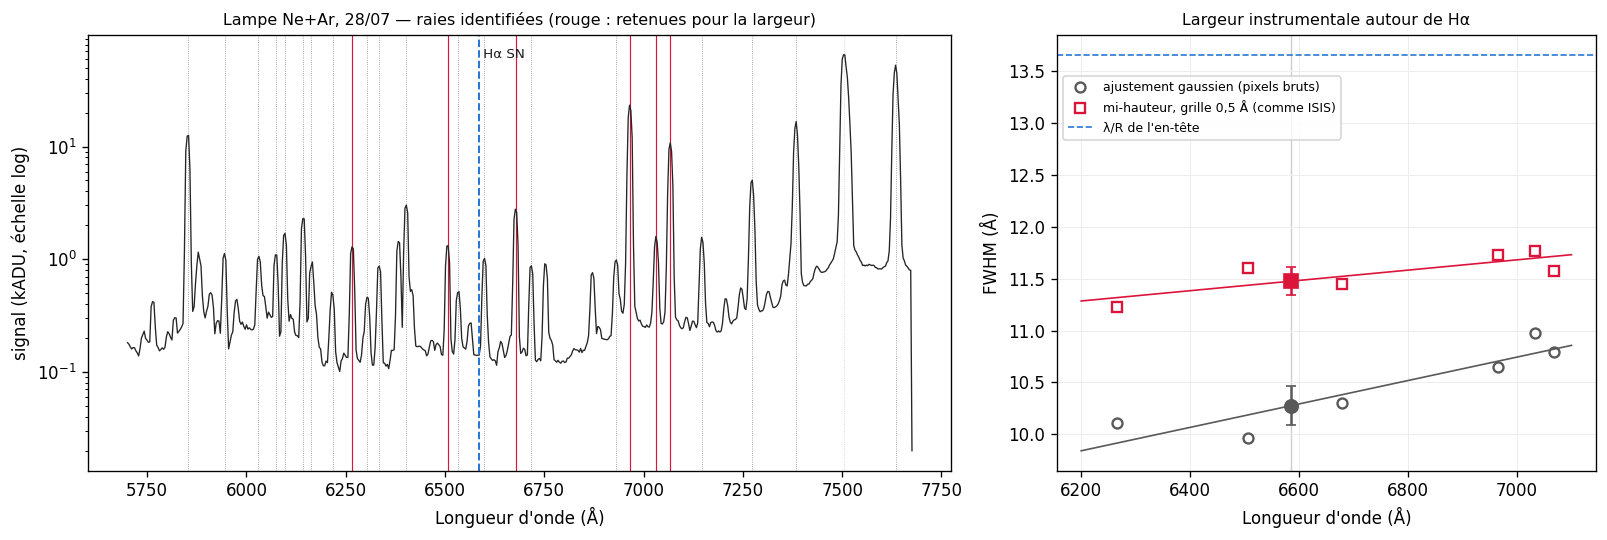

In [6]:
if NEON_PATH:
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw=dict(width_ratios=[1.6, 1]))
    m = np.polyval(coef, xpix) > 5700                # pas de raie de reference plus au bleu
    a1.plot(np.polyval(coef, xpix[m]), np.clip(neon[m], 20, None) / 1e3, color="0.15", lw=0.8)
    for k in np.where(ident)[0]:
        c = COUL_II if retenue[k] else ("0.55" if not sature[k] else "0.8")
        a1.axvline(lref[k], color=c, lw=0.7 if retenue[k] else 0.5, ls="-" if retenue[k] else ":",
                   zorder=0)
    a1.axvline(HA, color=COUL_IA, lw=1.2, ls="--")
    a1.text(HA, 0.97, " Hα SN", color="0.1", fontsize=8, transform=a1.get_xaxis_transform(),
            va="top")
    a1.set_yscale("log")
    a1.set_xlabel("Longueur d'onde (Å)"); a1.set_ylabel("signal (kADU, échelle log)")
    a1.set_title(f"Lampe Ne+Ar, 28/07 — raies identifiées (rouge : retenues pour la largeur)",
                 fontsize=9.5)

    ll = np.linspace(*FEN_INST, 50)
    for fw, p, mk, c, lab in [(fw_gauss, g_p, "o", "0.35", "ajustement gaussien (pixels bruts)"),
                              (fw_demi, d_p, "s", COUL_II, "mi-hauteur, grille 0,5 Å (comme ISIS)")]:
        a2.plot(lref[retenue], fw[retenue], mk, color=c, ms=6, mfc="white", mew=1.4, label=lab)
        a2.plot(ll, np.polyval(p, ll), color=c, lw=1)
    a2.errorbar(HA, INST["fwhm"], yerr=INST["sig"], fmt="s", color=COUL_II, ms=8, capsize=3)
    a2.errorbar(HA, INST["fwhm_gauss"], yerr=INST["sig_gauss"], fmt="o", color="0.35", ms=8, capsize=3)
    a2.axhline(HA / SPECTRES[-1]["R"], color=COUL_IA, lw=1, ls="--", label="λ/R de l'en-tête")
    a2.axvline(HA, color="0.8", lw=0.8, zorder=0)
    a2.set_xlabel("Longueur d'onde (Å)"); a2.set_ylabel("FWHM (Å)")
    a2.set_title("Largeur instrumentale autour de Hα", fontsize=9.5)
    a2.legend(fontsize=7.5, loc="upper left", bbox_to_anchor=(0, 0.92)); a2.grid(color="0.93", lw=0.6)
    plt.tight_layout(); plt.show()

## 6 — Hα : largeur à mi-hauteur et vitesse du gaz

1. continu local = droite ajustée sur deux fenêtres de part et d'autre de la raie ;
2. FWHM_obs = écart entre les deux passages à mi-hauteur (même fonction que pour la lampe) ;
3. largeur instrumentale Δλ mesurée au §5, retirée en quadrature :
   FWHM_vraie = √(FWHM_obs² − Δλ²) ;
4. incertitude par Monte-Carlo (500 tirages) : bruit du spectre, tiré au niveau mesuré dans les
   fenêtres de continu, et Δλ tirée selon sa propre incertitude.

**Encadrement.** La lampe éclaire toute la largeur de la fente, alors qu'une étoile au seeing
moyen n'en remplit qu'une partie : la largeur instrumentale *pour la supernova* est donc au plus
celle de la lampe. Il en découle :

* FWHM_vraie ≥ √(FWHM_obs² − Δλ_lampe²) : la valeur déconvoluée est une **borne basse** ;
* FWHM_vraie ≤ FWHM_obs, puisque l'instrument ne peut qu'élargir la raie : **borne haute**,
  indépendante de toute calibration. On retient FWHM_obs + 2σ.

Deux réserves : NGC 3310 est une galaxie à flambée de formation stellaire, donc la fente capte
aussi de l'Hα de régions H II ; et [N II] 6583 de l'hôte tombe à 2 Å de Hα. Ces deux
contaminations sont étroites et ne peuvent qu'*abaisser* la FWHM apparente.

In [7]:
FEN_CONT = [(6380, 6480), (6680, 6820)]     # A observes, hors Hα et hors bande O2 B
FEN_PIC  = 25                               # A, demi-fenetre de recherche du pic
N_MC     = 500

def continu_ha(wave, flux):
    m = np.zeros_like(wave, bool)
    for a, b in FEN_CONT:
        m |= (wave >= a) & (wave <= b)
    p = np.polyfit(wave[m], flux[m], 1)
    return np.polyval(p, wave), np.std(flux[m] - np.polyval(p, wave[m]))

def deconv(fw, inst):
    return np.sqrt(np.clip(fw**2 - inst**2, 0, None))

rng = np.random.default_rng(1)
print(f"largeur instrumentale : {INST['fwhm']:.2f} ± {INST['sig']:.2f} A ({INST['source']})\n")
print(f"{'date':12s}{'pic (A)':>9s}{'pic/cont':>9s}{'FWHM obs':>13s}{'FWHM vraie':>15s}"
      f"{'v_FWHM vraie':>15s}{'borne haute (2σ)':>20s}")
for s in SPECTRES:
    cont, rms = continu_ha(s["wave"], s["flux"])
    y = s["flux"] - cont
    fw, wpic, hpic, wb, wr = largeur_mi_hauteur(s["wave"], y, HA, FEN_PIC)
    t_obs  = np.array([largeur_mi_hauteur(s["wave"], y + rng.normal(0, rms, y.size), HA, FEN_PIC)[0]
                       for _ in range(N_MC)])
    t_inst = rng.normal(INST["fwhm"], INST["sig"], N_MC)
    t_vr   = deconv(t_obs, t_inst)
    sfw    = t_obs.std()
    vraie  = deconv(fw, INST["fwhm"])
    sv     = t_vr.std() / wpic * C_KMS
    v_obs, v_vraie = fw / wpic * C_KMS, vraie / wpic * C_KMS
    v_lim = (fw + 2 * sfw) / wpic * C_KMS
    s["ha"] = dict(cont=cont, y=y, rms=rms, fw=fw, sfw=sfw, wpic=wpic, hpic=hpic, wb=wb, wr=wr,
                   inst=INST["fwhm"], vraie=vraie, v_obs=v_obs, v_vraie=v_vraie,
                   sv=sv, v_lim=v_lim)
    print(f"{s['date']:12s}{wpic:9.1f}{1 + hpic / np.interp(wpic, s['wave'], cont):9.2f}"
          f"{fw:8.2f} ± {sfw:.2f}{vraie:10.1f} Å"
          f"{v_vraie:8.0f} ± {sv:3.0f} km/s   < {v_lim:4.0f} km/s")

print(f"\nlargeur instrumentale seule : {INST['fwhm'] / HA * C_KMS:.0f} km/s ; "
      f"± = ecart-type Monte-Carlo (bruit + incertitude sur Δλ)")

largeur instrumentale : 11.48 ± 0.13 A (lampe Ne+Ar, mi-hauteur à 0,5 Å/px)

date          pic (A) pic/cont     FWHM obs     FWHM vraie   v_FWHM vraie    borne haute (2σ)
2026-07-18     6585.0     3.03   13.09 ± 0.28       6.3 Å     286 ±  30 km/s   <  621 km/s
2026-07-23     6584.5     2.93   12.16 ± 0.17       4.0 Å     183 ±  31 km/s   <  570 km/s
2026-07-28     6584.5     2.56   13.02 ± 0.26       6.2 Å     280 ±  30 km/s   <  617 km/s

largeur instrumentale seule : 523 km/s ; ± = ecart-type Monte-Carlo (bruit + incertitude sur Δλ)


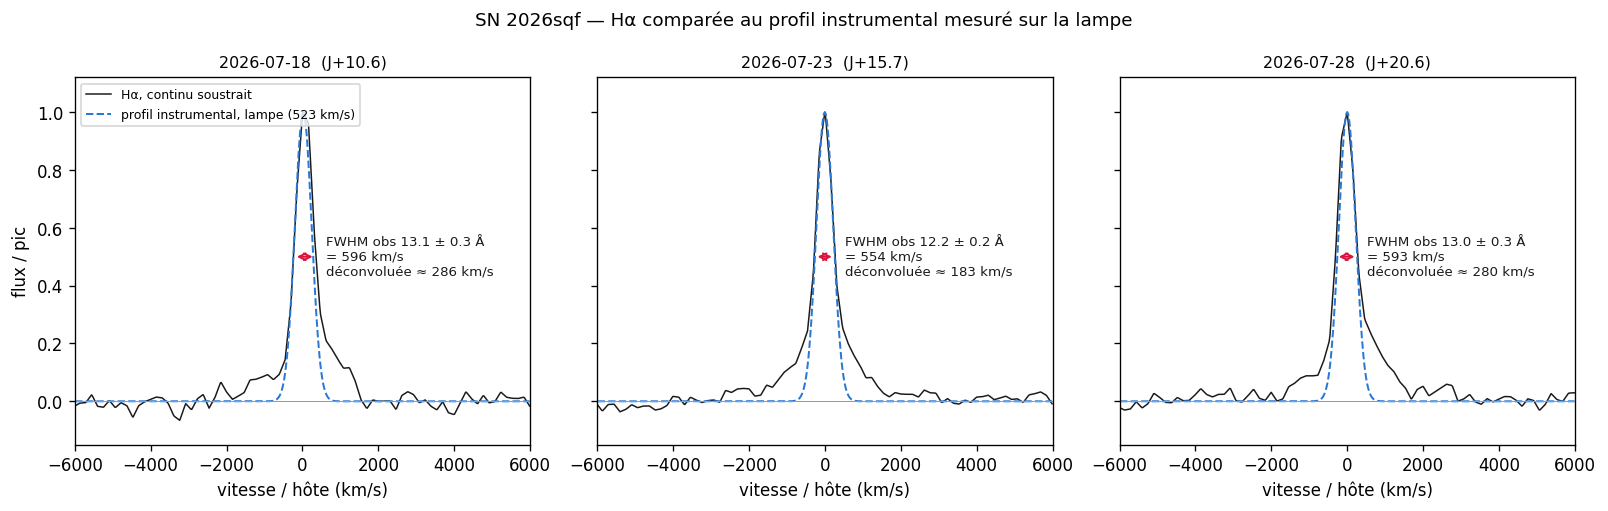

In [8]:
def gauss(x, fw):
    return np.exp(-4 * np.log(2) * (x / fw) ** 2)

fig, axs = plt.subplots(1, len(SPECTRES), figsize=(13.5, 4.3), sharey=True)
for ax, s in zip(np.atleast_1d(axs), SPECTRES):
    h = s["ha"]
    v = (s["wave"] - HA) / HA * C_KMS
    m = np.abs(v) < 6000
    ax.plot(v[m], h["y"][m] / h["hpic"], color="0.1", lw=0.9, label="Hα, continu soustrait")
    vi = h["inst"] / HA * C_KMS
    vc = (h["wpic"] - HA) / HA * C_KMS
    ax.plot(v[m], gauss(v[m] - vc, vi), color=COUL_IA, lw=1.2, ls="--",
            label=f"profil instrumental, lampe ({vi:.0f} km/s)")
    vb, vr = [(w - HA) / HA * C_KMS for w in (h["wb"], h["wr"])]
    ax.annotate("", (vb, 0.5), (vr, 0.5), arrowprops=dict(arrowstyle="<->", color=COUL_II, lw=1.2))
    ax.text(vr + 250, 0.5, f"FWHM obs {h['fw']:.1f} ± {h['sfw']:.1f} Å\n"
            f"= {h['v_obs']:.0f} km/s\ndéconvoluée ≈ {h['v_vraie']:.0f} km/s",
            fontsize=8, va="center", color="0.1")
    ax.axhline(0, color="0.6", lw=0.6)
    ax.set_xlim(-6000, 6000); ax.set_ylim(-0.15, 1.12)
    ax.set_xlabel("vitesse / hôte (km/s)")
    ax.set_title(s["label"], fontsize=9.5)
np.atleast_1d(axs)[0].set_ylabel("flux / pic")
np.atleast_1d(axs)[0].legend(fontsize=7.5, loc="upper left")
fig.suptitle(f"{OBJET} — Hα comparée au profil instrumental mesuré sur la lampe", fontsize=11)
plt.tight_layout(); plt.show()

Lecture de la figure : si le cœur de Hα (noir) épouse le profil instrumental (bleu tireté), la
composante étroite n'est pas résolue. Des **ailes** qui débordent du profil instrumental à la base
signaleraient en revanche une composante de largeur intermédiaire (1 000–2 000 km/s), typique de la
zone choquée et fréquente dans les Ia-CSM comme dans les IIn.

## 7 — Si II 6355 émerge-t-il ? Pseudo-largeur équivalente

Même définition que pour SN 2026aaiv : le pseudo-continu est la droite qui joint les deux maxima
encadrant la plage attendue de l'absorption, et on intègre le déficit de flux sous cette droite.
Pour une Ia normale près du maximum, pEW(Si II 6355) vaut ~ 80–130 Å (Branch et al. 2006). Dans une
Ia-CSM, le continu d'interaction dilue la raie : une pEW nulle ou faible, compatible avec le bruit,
ne permet pas de trancher entre IIn et Ia-CSM.

L'incertitude combine le bruit du spectre et un déplacement aléatoire de ± 15 Å des ancres.

date          phase     ancres (A)    pEW Si II 6355  signif.
2026-07-18    10.6j    5910 / 6247       17.5 ± 6.2 Å    2.8 σ
2026-07-23    15.7j    5906 / 6332       19.0 ± 5.3 Å    3.5 σ
2026-07-28    20.6j    5908 / 6382       30.0 ± 6.3 Å    4.8 σ


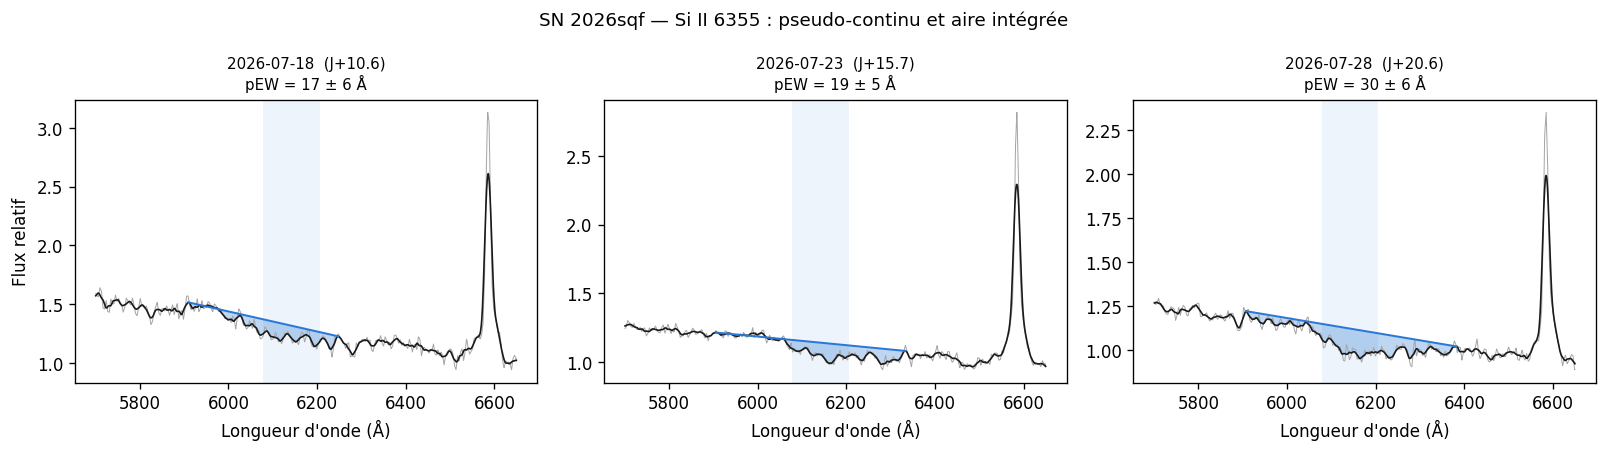

In [9]:
FEN_ANCRE_B = (5900, 6070)      # maximum bleu du pseudo-continu (A observes)
FEN_ANCRE_R = (6230, 6420)      # maximum rouge
LISS_PEW    = 31                # px

def pew(wave, y, wb, wr):
    fb, fr = np.interp(wb, wave, y), np.interp(wr, wave, y)
    m  = (wave >= wb) & (wave <= wr)
    pc = fb + (fr - fb) * (wave[m] - wb) / (wr - wb)
    return trapz(1 - y[m] / pc, wave[m])

def maximum(wave, y, fen):
    m = (wave >= fen[0]) & (wave <= fen[1])
    return wave[m][np.argmax(y[m])]

rng = np.random.default_rng(0)
print(f"{'date':12s}{'phase':>7s}{'ancres (A)':>15s}{'pEW Si II 6355':>18s}{'signif.':>9s}")
for s in SPECTRES:
    wave, flux = s["wave"], s["flux"]
    yl  = uniform_filter1d(flux, LISS_PEW)
    wb, wr = maximum(wave, yl, FEN_ANCRE_B), maximum(wave, yl, FEN_ANCRE_R)
    p0  = pew(wave, yl, wb, wr)
    rms = np.std(flux - yl)
    tirs = []
    for _ in range(400):
        y = uniform_filter1d(flux + rng.normal(0, rms, flux.size), LISS_PEW)
        j = rng.uniform(-15, 15, 2)
        tirs.append(pew(wave, y, wb + j[0], wr + j[1]))
    sp = np.std(tirs)
    s["si"] = dict(yl=yl, wb=wb, wr=wr, pew=p0, s=sp)
    print(f"{s['date']:12s}{s['phase']:6.1f}j{wb:8.0f} / {wr:.0f}{p0:11.1f} ± {sp:.1f} Å"
          f"{p0 / sp:7.1f} σ")

fig, axs = plt.subplots(1, len(SPECTRES), figsize=(13.5, 3.8), sharey=False)
for ax, s in zip(np.atleast_1d(axs), SPECTRES):
    wave, si = s["wave"], s["si"]
    m = (wave > 5700) & (wave < 6650)
    ax.plot(wave[m], s["flux"][m], color="0.65", lw=0.6)
    ax.plot(wave[m], si["yl"][m], color="0.1", lw=1.0)
    fb, fr = np.interp([si["wb"], si["wr"]], wave, si["yl"])
    mm = (wave >= si["wb"]) & (wave <= si["wr"])
    pc = fb + (fr - fb) * (wave[mm] - si["wb"]) / (si["wr"] - si["wb"])
    ax.plot([si["wb"], si["wr"]], [fb, fr], color=COUL_IA, lw=1.2)
    ax.fill_between(wave[mm], si["yl"][mm], pc, where=si["yl"][mm] < pc, color=COUL_IA,
                    alpha=0.3, lw=0)
    a, b = bande_ia(6355)
    ax.axvspan(a, b, color=COUL_IA, alpha=0.08, lw=0)
    ax.set_title(f"{s['label']}\npEW = {si['pew']:.0f} ± {si['s']:.0f} Å", fontsize=9)
    ax.set_xlabel("Longueur d'onde (Å)")
np.atleast_1d(axs)[0].set_ylabel("Flux relatif")
fig.suptitle(f"{OBJET} — Si II 6355 : pseudo-continu et aire intégrée", fontsize=11)
plt.tight_layout(); plt.show()

## 8 — Suivi temporel

Deux présentations à tester :

* **A — flux relatif brut.** Les spectres tels que sortis d'ISIS, sur le même axe. ISIS les ramène
  tous à ~1 vers 6600–6700 Å : la comparaison montre surtout l'**évolution de la pente du
  continu**, c'est-à-dire le refroidissement. Elle ne vaut que si la réponse instrumentale et la
  correction d'extinction différentielle sont fiables pour les trois nuits.
* **B — spectres normalisés.** En haut, chaque spectre est divisé par sa médiane sur une fenêtre
  de continu (`FEN_NORM`), puis décalé verticalement. En bas, zooms sur Hβ et Hα en vitesse, divisés
  par le continu local : l'évolution de l'intensité relative des raies étroites ressort.

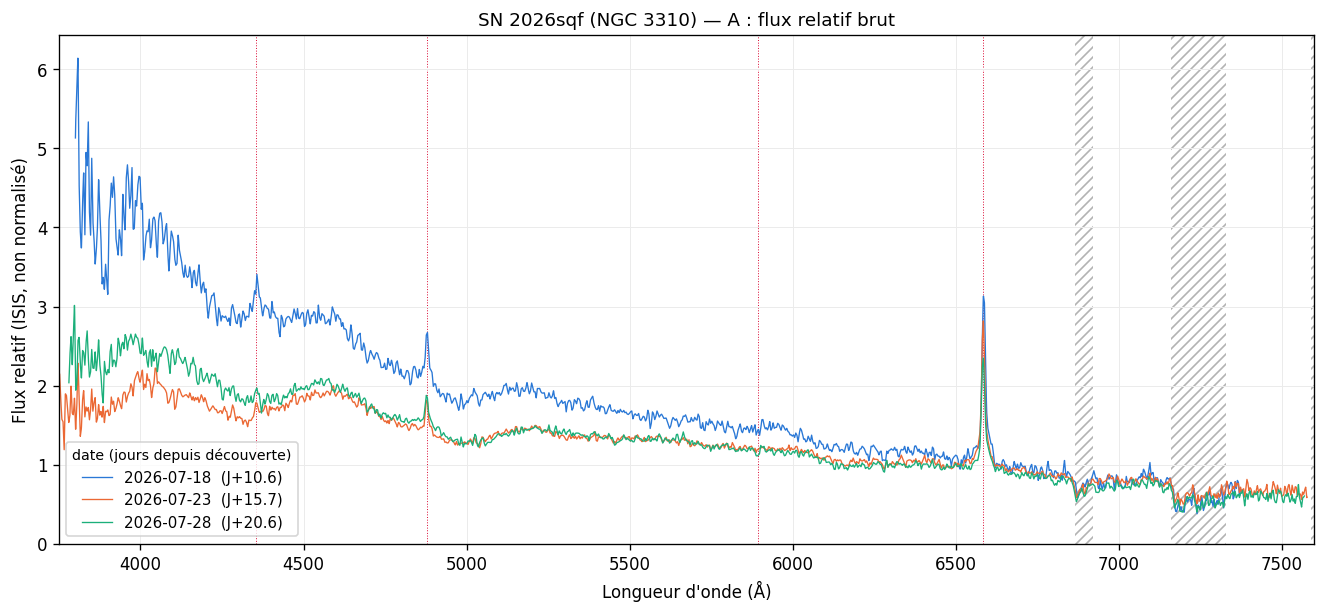

In [10]:
COUL_EPOQUE = ["#2a78d6", "#eb6834", "#1baf7a"]   # bleu, orange, vert d'eau (ordre chronologique)
FEN_NORM    = (5500, 5700)                        # A, continu sans raie forte
DECALAGE    = 0.8

# --- A : flux relatif brut ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(13.5, 5.5))
for s, c in zip(SPECTRES, COUL_EPOQUE):
    ax.plot(s["wave"], s["flux"], color=c, lw=0.8, label=s["label"])
for a, b, lab in TELLUR:
    ax.axvspan(a, b, fc="none", ec="0.7", hatch="////", lw=0, zorder=0)
for lam0, lab, _ in EMISSION:
    ax.axvline(lam0 * (1 + Z_HOTE), color=COUL_II, lw=0.6, ls=":", zorder=0)
ax.set_xlim(3750, 7600); ax.set_ylim(0, None)
ax.set_xlabel("Longueur d'onde (Å)"); ax.set_ylabel("Flux relatif (ISIS, non normalisé)")
ax.grid(color="0.92", lw=0.6); ax.set_axisbelow(True)
ax.legend(fontsize=9, title="date (jours depuis découverte)", title_fontsize=8.5)
ax.set_title(f"{OBJET} ({HOTE}) — A : flux relatif brut", fontsize=11)
plt.show()

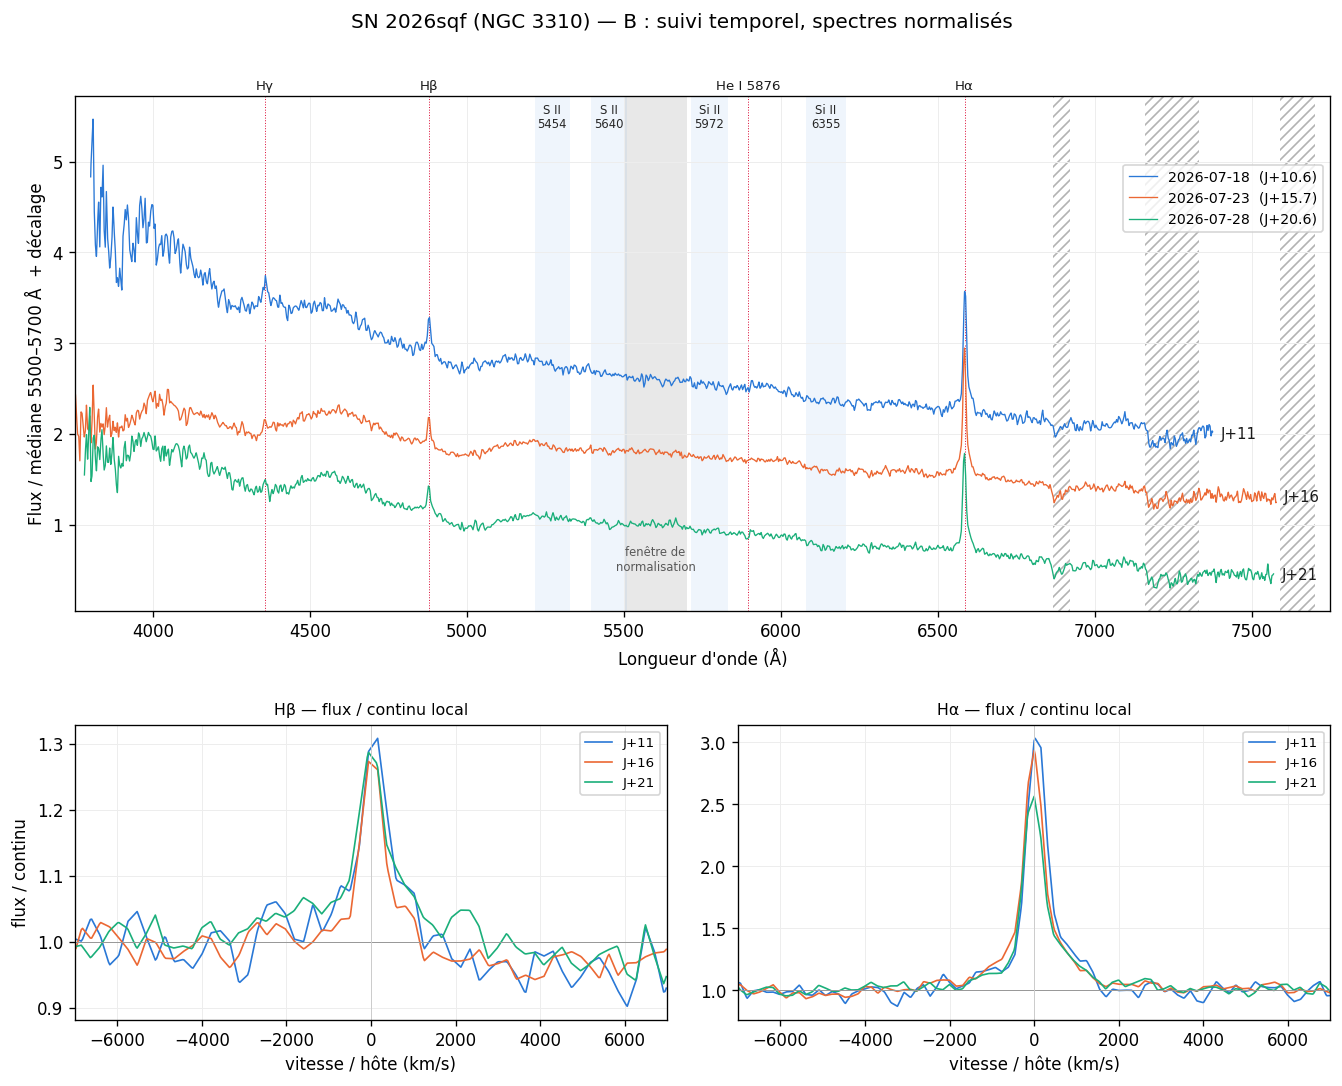

In [11]:
# --- B : normalises + zooms Balmer -----------------------------------------------------
fig = plt.figure(figsize=(13.5, 10))
gs  = fig.add_gridspec(2, 2, height_ratios=[1.75, 1], hspace=0.28, wspace=0.12)
ax  = fig.add_subplot(gs[0, :])

n = len(SPECTRES)
for k, (s, c) in enumerate(zip(SPECTRES, COUL_EPOQUE)):
    wave = s["wave"]
    mn   = (wave >= FEN_NORM[0]) & (wave <= FEN_NORM[1])
    s["norm"] = s["flux"] / np.median(s["flux"][mn])
    off  = (n - 1 - k) * DECALAGE                      # le plus ancien en haut
    ax.plot(wave, s["norm"] + off, color=c, lw=0.8, label=s["label"])
    ax.text(wave[-1] + 25, np.median(s["norm"][-200:]) + off, f"J+{s['phase']:.0f}",
            color="0.1", fontsize=9, va="center")
ax.axvspan(*FEN_NORM, color="0.85", alpha=0.6, lw=0, zorder=0)
ax.text(np.mean(FEN_NORM), 0.08, "fenêtre de\nnormalisation", ha="center", fontsize=7,
        color="0.35", transform=ax.get_xaxis_transform())
for a, b, lab in TELLUR:
    ax.axvspan(a, b, fc="none", ec="0.7", hatch="////", lw=0, zorder=0)
for lam0, lab, _ in EMISSION:
    w0 = lam0 * (1 + Z_HOTE)
    ax.axvline(w0, color=COUL_II, lw=0.6, ls=":", zorder=0)
    ax.text(w0, 1.005, lab, ha="center", va="bottom", fontsize=8, color="0.1",
            transform=ax.get_xaxis_transform())
for lam0, lab, _ in ABS_IA:
    ax.axvspan(*bande_ia(lam0), color=COUL_IA, alpha=0.07, lw=0, zorder=0)
    ax.text(np.mean(bande_ia(lam0)), 0.985, "\n".join(lab.rsplit(" ", 1)), ha="center", va="top",
            fontsize=7, color="0.15", linespacing=1.1, transform=ax.get_xaxis_transform())
ax.set_xlim(3750, 7750)
ax.set_xlabel("Longueur d'onde (Å)")
ax.set_ylabel(f"Flux / médiane {FEN_NORM[0]}–{FEN_NORM[1]} Å  + décalage")
ax.legend(fontsize=8.5, loc="upper right", bbox_to_anchor=(1, 0.88))
ax.grid(color="0.93", lw=0.6); ax.set_axisbelow(True)

# zooms : flux / continu local, en vitesse
ZOOMS = [(4861.33, "Hβ", [(4720, 4800), (4960, 5040)]),
         (6562.80, "Hα", FEN_CONT)]
for j, (lam0, lab, fens) in enumerate(ZOOMS):
    az = fig.add_subplot(gs[1, j], sharey=None)
    l0 = lam0 * (1 + Z_HOTE)
    for s, c in zip(SPECTRES, COUL_EPOQUE):
        wave, flux = s["wave"], s["flux"]
        m = np.zeros_like(wave, bool)
        for a, b in fens:
            m |= (wave >= a) & (wave <= b)
        cont = np.polyval(np.polyfit(wave[m], flux[m], 1), wave)
        v = (wave - l0) / l0 * C_KMS
        mv = np.abs(v) < 7000
        az.plot(v[mv], flux[mv] / cont[mv], color=c, lw=1.0, label=f"J+{s['phase']:.0f}")
    az.axhline(1, color="0.6", lw=0.6); az.axvline(0, color="0.8", lw=0.6)
    az.set_xlim(-7000, 7000)
    az.set_xlabel("vitesse / hôte (km/s)")
    az.set_title(f"{lab} — flux / continu local", fontsize=9.5)
    az.grid(color="0.93", lw=0.6); az.set_axisbelow(True)
    if j == 0:
        az.set_ylabel("flux / continu")
    az.legend(fontsize=8, loc="upper right")

fig.suptitle(f"{OBJET} ({HOTE}) — B : suivi temporel, spectres normalisés", fontsize=12, y=0.95)
plt.show()

## 9 — Bilan chiffré

In [12]:
print(f"largeur instrumentale a Hα : {INST['fwhm']:.2f} ± {INST['sig']:.2f} A ({INST['source']})"
      f", R optique ≈ {INST['R']:.0f}\n")
print(f"{'date':12s}{'phase':>7s}{'Hα FWHM obs':>15s}{'v déconvoluée':>19s}"
      f"{'v < (2σ)':>11s}{'pEW Si II 6355':>18s}")
for s in SPECTRES:
    h, si = s["ha"], s["si"]
    print(f"{s['date']:12s}{s['phase']:6.1f}j{h['fw']:9.2f} ± {h['sfw']:.2f} Å"
          f"{h['v_vraie']:9.0f} ± {h['sv']:3.0f} km/s"
          f"{h['v_lim']:7.0f} km/s{si['pew']:10.1f} ± {si['s']:.1f} Å")

largeur instrumentale a Hα : 11.48 ± 0.13 A (lampe Ne+Ar, mi-hauteur à 0,5 Å/px), R optique ≈ 641

date          phase    Hα FWHM obs      v déconvoluée   v < (2σ)    pEW Si II 6355
2026-07-18    10.6j    13.09 ± 0.28 Å      286 ±  30 km/s    621 km/s      17.5 ± 6.2 Å
2026-07-23    15.7j    12.16 ± 0.17 Å      183 ±  31 km/s    570 km/s      19.0 ± 5.3 Å
2026-07-28    20.6j    13.02 ± 0.26 Å      280 ±  30 km/s    617 km/s      30.0 ± 6.3 Å


## Références

* Silverman et al. (2013), ApJS 207, 3 — *Type Ia supernovae strongly interacting with their
  circumstellar medium* : définition et propriétés spectrales des Ia-CSM.
* Leloudas et al. (2015), A&A 574, A61 — dilution des raies de Ia par le continu d'interaction ;
  pourquoi une Ia-CSM peut passer pour une IIn.
* Schlegel (1990), MNRAS 244, 269 — définition des SN IIn.
* Branch et al. (2006), PASP 118, 560 — pEW de Si II dans les Ia.
* Wyman, Sloan & Shirley (2013), JCGT 2(2) — fonctions colorimétriques CIE analytiques.
* arXiv:2608.13321 — *JWST detects a dusty AGB-like source before the Type Ia-CSM supernova 2026sqf*.